# SESA standardized anomalies: ERA5-Land, MERRA-2, GLEAM and CRU scPDSI (1980–2024)

How have standardized anomalies over southeastern South America (20–40°S, 65–40°W) changed, and do the datasets agree?

**Method:** 

* Each dataset on its own grid, cut to the SESA box. 
* Per grid cell, standardized anomalies `(x − mean) / std` against `REF_PERIOD` _(default: the full 1980–2024 period)_, computed separately for each season (DJF, MAM, JJA, SON; DJF labelled by the January year) and for each calendar month. Then the cos(latitude) area-weighted mean over the box (cells with no data are skipped).


## Notes
- **Area-weighted mean of standardized anomalies:** Each cell is standardized first, then averaged, so every cell counts equally per unit area regardless of how variable it is.
- **Grids:** (ERA5-Land and GLEAM 0.1°, MERRA-2 and CRU 0.5°).
- **Climatology:** With `REF_PERIOD = YEARS`, every dataset has zero mean over 1980–2024 (can change later). Need to select for the climate models for the longer term.

## Imports

In [29]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

warnings.filterwarnings("ignore", message="All-NaN slice")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Degrees of freedom")
%matplotlib inline

## Settings

In [3]:
YEARS = (1980, 2024)                   # analysis period
REF_PERIOD = (1980, 2024)              # climatology for the standardized anomalies (full period)
REGION = dict(lat=(-40.0, -20.0), lon=(-65.0, -40.0))   # SESA box
SPLIT_YEAR = 2002                      # histograms compare YEARS[0]..SPLIT_YEAR-1 with SPLIT_YEAR..YEARS[1]

DATASETS = {
    "ERA5-Land": dict(path="/home/andish/data/ERA5-Land_Update_Oct_2026.grib", kind="era5_grib",
                      fallback=dict(path="/home/andish/data/sm/ERA5_ROOT.nc", var="root_zone_sm")),
    # netCDF alternative (0.5 deg ERA5 root-zone SM, 1940-2025):
    # "ERA5-Land": dict(path="/home/andish/data/sm/ERA5_ROOT.nc", var="root_zone_sm"),
    "MERRA-2": dict(path="/home/andish/ROOTS/data/merra2_processed_1980-2025.nc", var="rootzone_soil_moisture"),
    "GLEAM v4.3a": dict(path="/home/andish/data/SMrz_v4.3a/SMrz_*_GLEAM_v4.3a_MO.nc", var="SMrz"),
    "CRU scPDSI": dict(path="/home/andish/data/PDSI_CRU_1903_2025.nc", var="scpdsi"),
}
ERA5_LAYERS = {"swvl1": 7.0, "swvl2": 21.0, "swvl3": 72.0}   # layer thickness (cm) -> 0-100 cm root zone

COLORS = {"ERA5-Land": "#1f78b4", "MERRA-2": "#33a02c", "GLEAM v4.3a": "#e66101", "CRU scPDSI": "#6a3d9a"}
SEASONS = ["DJF", "MAM", "JJA", "SON"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

OUT_DIR = "../Outputs/SESA_std_anomalies"
FIG_DIR = "../Figures/SESA_std_anomalies"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

## Load each dataset over the SESA box

In [4]:
def tidy(da, region=None):
    # common layout: (time, lat, lon), lon in -180..180, lat ascending, SESA box, month-start time, YEARS
    da = da.rename({k: v for k, v in {"latitude": "lat", "longitude": "lon"}.items() if k in da.dims or k in da.coords})
    da = da.assign_coords(lon=(((da["lon"] + 180) % 360) - 180)).sortby("lon").sortby("lat")
    region = REGION if region is None else region
    (la0, la1), (lo0, lo1) = region["lat"], region["lon"]
    da = da.sel(lat=slice(la0, la1), lon=slice(lo0, lo1)).transpose("time", "lat", "lon")
    t = pd.to_datetime(pd.DataFrame({"year": da["time"].dt.year.values, "month": da["time"].dt.month.values, "day": 1}))
    da = da.assign_coords(time=t.values)
    if len(np.unique(t)) < len(t):                       # sub-monthly input -> monthly means
        da = da.groupby("time").mean()
    da = da.sel(time=slice(f"{YEARS[0]}-01-01", f"{YEARS[1]}-12-31"))
    da = da.drop_vars([c for c in da.coords if c not in ("time", "lat", "lon")])
    return da.astype("float32").load()


def open_nc(cfg):
    files = sorted(glob.glob(cfg["path"]))
    if not files:
        raise FileNotFoundError(cfg["path"])
    ds = xr.open_mfdataset(files, combine="by_coords", chunks={}) if len(files) > 1 else xr.open_dataset(files[0])
    return ds[cfg["var"]]


def open_era5_grib(cfg):
    # ERA5-Land GRIB -> 0-100 cm root-zone SM as the thickness-weighted mean of swvl1-3
    import cfgrib
    groups = cfgrib.open_datasets(cfg["path"])
    layers = {}
    for ds in groups:
        for v in ERA5_LAYERS:
            if v in ds.data_vars:
                da = ds[v]
                if "step" in da.dims:                     # monthly means come with a step dim of length 1
                    da = da.mean("step")
                if "time" not in da.dims and "valid_time" in da.dims:
                    da = da.rename(valid_time="time")
                layers[v] = da.drop_vars([c for c in da.coords if c not in ("time", "latitude", "longitude")])
    if not layers:
        raise KeyError(f"no swvl1-3 in {cfg['path']}; groups hold: {[list(d.data_vars) for d in groups]}")
    if len(layers) < len(ERA5_LAYERS):
        print("ERA5-Land: only", sorted(layers), "found; root zone uses those layers")
    w = {v: ERA5_LAYERS[v] for v in layers}
    return sum(layers[v] * w[v] for v in layers) / sum(w.values())


def load_dataset(name, cfg, region=None):
    try:
        raw = open_era5_grib(cfg) if cfg.get("kind") == "era5_grib" else open_nc(cfg)
    except (ImportError, OSError, KeyError, ValueError, RuntimeError) as err:   # RuntimeError: ecCodes library missing
        if "fallback" not in cfg:
            raise
        print(f"{name}: could not read {cfg['path']} ({type(err).__name__}: {err}); using {cfg['fallback']['path']}")
        raw = open_nc(cfg["fallback"])
    return tidy(raw, region)


data = {}
for name, cfg in DATASETS.items():
    data[name] = load_dataset(name, cfg)
    d = data[name]
    print(f"{name:12s} {str(d.time.values[0])[:7]} to {str(d.time.values[-1])[:7]} | grid {d.sizes['lat']}x{d.sizes['lon']}")
    if int(d.time.dt.year.min()) > YEARS[0] or int(d.time.dt.year.max()) < YEARS[1]:
        print(f"   WARNING: {name} does not cover {YEARS[0]}-{YEARS[1]}")


ERA5-Land: could not read /home/andish/data/ERA5-Land_Update_Oct_2026.grib (RuntimeError: Cannot find the ecCodes library); using /home/andish/data/sm/ERA5_ROOT.nc


/home/andish/.conda/envs/pangeo-andish/lib/python3.12/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


ERA5-Land    1980-01 to 2024-12 | grid 40x50
MERRA-2      1980-01 to 2024-12 | grid 40x50
GLEAM v4.3a  1980-01 to 2024-12 | grid 200x250
CRU scPDSI   1980-01 to 2024-12 | grid 40x50


## Standardized anomalies and SESA area-weighted means

In [5]:
SEASON_MONTHS = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}


def seasonal(da, season):
    # seasonal mean on a 'year' dim (DJF labelled by the January year); incomplete seasons -> NaN
    months = SEASON_MONTHS[season]
    sel = da.where(da["time"].dt.month.isin(months), drop=True)
    year = (sel["time"].dt.year + ((sel["time"].dt.month == 12) & (season == "DJF"))).rename("year")
    mean = sel.groupby(year).mean("time")
    count = sel.notnull().groupby(year).sum("time")
    return mean.where(count == len(months))


def std_anom_seasonal(x):
    ref = x.sel(year=slice(*REF_PERIOD))
    sd = ref.std("year")
    return (x - ref.mean("year")) / sd.where(sd > 0)


def std_anom_monthly(da):
    # each calendar month against its own climatology
    ref = da.sel(time=slice(f"{REF_PERIOD[0]}-01-01", f"{REF_PERIOD[1]}-12-31"))
    mean = ref.groupby("time.month").mean("time")
    sd = ref.groupby("time.month").std("time")
    z = (da.groupby("time.month") - mean).groupby("time.month") / sd.where(sd > 0)
    return z.drop_vars("month")


def area_mean(z):
    # cos(lat) area-weighted mean over the box; NaN cells (ocean / missing) are skipped
    return z.weighted(np.cos(np.deg2rad(z["lat"]))).mean(("lat", "lon"))


# seasonal: seas[season] -> DataFrame (year x dataset)
seas = {s: pd.DataFrame({n: area_mean(std_anom_seasonal(seasonal(d, s))).to_series() for n, d in data.items()})
        .loc[YEARS[0]:YEARS[1]] for s in SEASONS}
# monthly: mon -> DataFrame (month-start time x dataset)
mon = pd.DataFrame({n: area_mean(std_anom_monthly(d)).to_series() for n, d in data.items()})
mon.index.name = "time"

pd.concat(seas, names=["season", "year"]).to_csv(os.path.join(OUT_DIR, "sesa_std_anom_seasonal.csv"))
mon.to_csv(os.path.join(OUT_DIR, "sesa_std_anom_monthly.csv"))
seas["DJF"].tail()

,ERA5-Land,MERRA-2,GLEAM v4.3a,CRU scPDSI
year,,,,
2020,-0.273914,-0.468673,-0.756468,-0.528566
2021,-0.441647,-0.589827,-0.769130,-1.283711
2022,-0.842038,-0.933274,-1.423502,-1.501304
2023,-0.746199,-0.879677,-0.942327,-1.677182
2024,-0.374941,-0.418603,-0.283551,-0.627341


In [9]:
def sen_trend(y, t):
    # Sen slope (per decade) and Mann-Kendall-type p-value (Kendall tau, no pre-whitening)
    ok = np.isfinite(y)
    if ok.sum() < 5:
        return np.nan, np.nan, np.nan
    slope, intercept, _, _ = stats.theilslopes(y[ok], t[ok])
    p = stats.kendalltau(t[ok], y[ok]).pvalue
    return slope * 10, intercept, p


rows = []
for s, df in seas.items():
    for n in df:
        sl, _, p = sen_trend(df[n].values, df.index.values.astype(float))
        rows.append(dict(season=s, dataset=n, sen_per_decade=sl, p=p))
seas_trends = pd.DataFrame(rows).pivot(index="season", columns="dataset", values="sen_per_decade").reindex(SEASONS)
seas_p = pd.DataFrame(rows).pivot(index="season", columns="dataset", values="p").reindex(SEASONS)
seas_trends.to_csv(os.path.join(OUT_DIR, "sesa_std_anom_seasonal_trends.csv"))
print("Sen slope of the box-mean anomaly (SD per decade); * = p < 0.05")
seas_trends.round(3).astype(str) + np.where(seas_p < 0.05, "*", "")

Sen slope of the box-mean anomaly (SD per decade); * = p < 0.05


dataset,CRU scPDSI,ERA5-Land,GLEAM v4.3a,MERRA-2
season,,,,
DJF,-0.228*,-0.169*,-0.309*,-0.189*
MAM,-0.197*,-0.183*,-0.275*,-0.147*
JJA,-0.238*,-0.271*,-0.287*,-0.184*
SON,-0.249*,-0.22*,-0.295*,-0.161*


## Figure 1: seasonal standardized anomalies, area-weighted over SESA

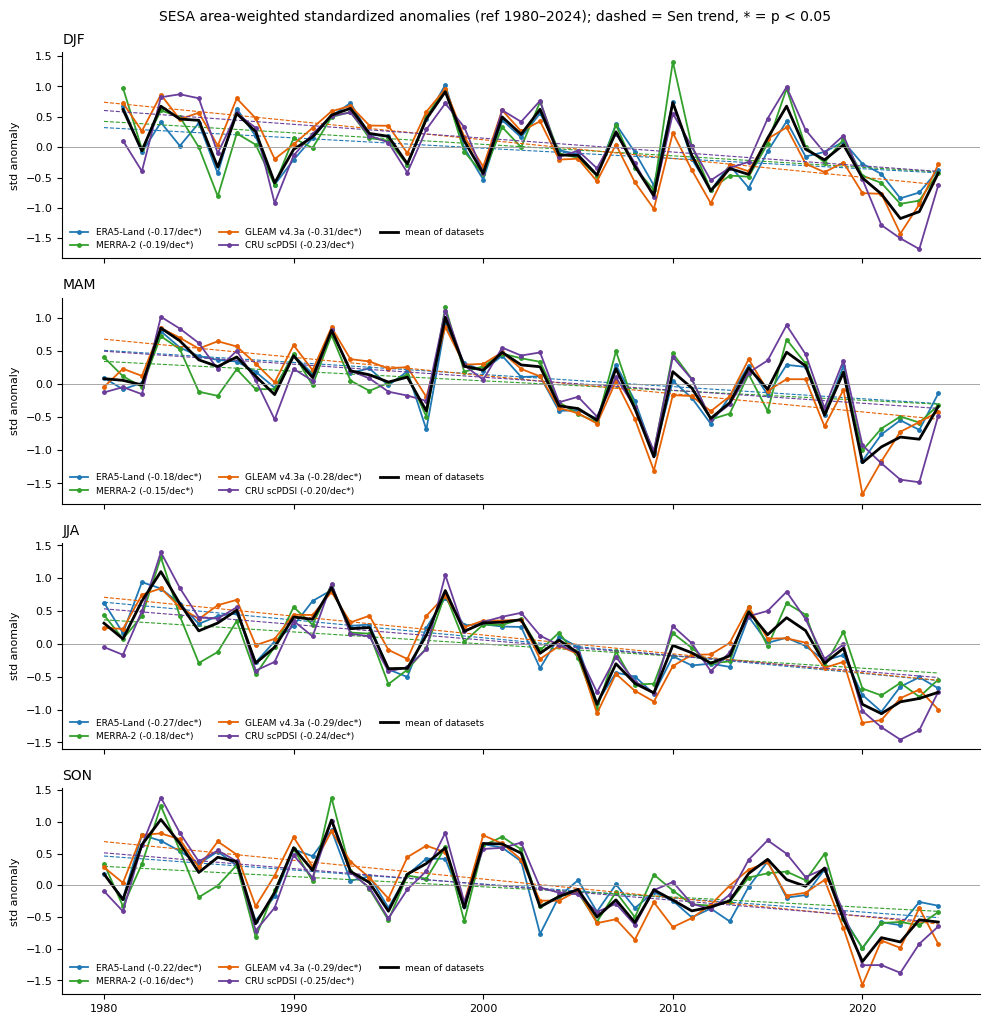

In [10]:
fig, axes = plt.subplots(len(SEASONS), 1, figsize=(10, 2.6 * len(SEASONS)), sharex=True)
for ax, s in zip(np.atleast_1d(axes), SEASONS):
    df = seas[s]
    t = df.index.values.astype(float)
    for n in df:
        sl, b, p = sen_trend(df[n].values, t)
        ax.plot(t, df[n], color=COLORS.get(n), lw=1.3, marker="o", ms=2.5,
                label=f"{n} ({sl:+.2f}/dec{'*' if p < 0.05 else ''})")
        ax.plot(t, b + sl / 10 * t, color=COLORS.get(n), lw=0.8, ls="--")
    ax.plot(t, df.mean(axis=1), color="k", lw=2.0, label="mean of datasets")
    ax.axhline(0, color="#999999", lw=0.6)
    ax.set_title(s, fontsize=10, loc="left")
    ax.set_ylabel("std anomaly", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=6.5, frameon=False, ncol=3, loc="lower left")
fig.suptitle(f"SESA area-weighted standardized anomalies (ref {REF_PERIOD[0]}–{REF_PERIOD[1]}); dashed = Sen trend, * = p < 0.05",
             fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_seasonal.png"), dpi=200, bbox_inches="tight")
plt.show()

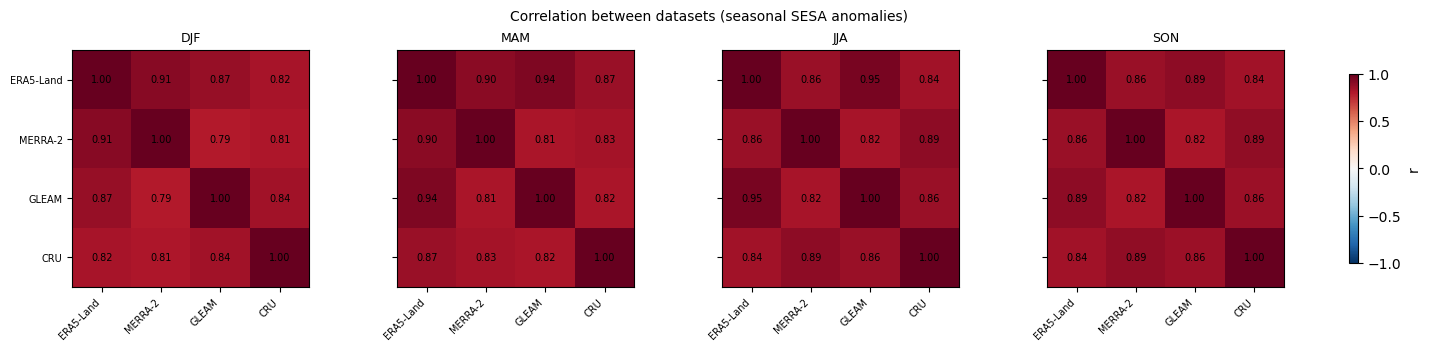

In [11]:
# how well do the datasets agree? Pearson r of the seasonal box-mean anomalies
fig, axes = plt.subplots(1, len(SEASONS), figsize=(3.6 * len(SEASONS), 3.4), constrained_layout=True)
for ax, s in zip(np.atleast_1d(axes), SEASONS):
    r = seas[s].corr()
    im = ax.imshow(r.values, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(r)), [c.split()[0] for c in r.columns], rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(len(r)), [c.split()[0] for c in r.index] if ax is np.atleast_1d(axes)[0] else [], fontsize=7)
    for i in range(len(r)):
        for j in range(len(r)):
            ax.text(j, i, f"{r.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(s, fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8, label="r")
fig.suptitle("Correlation between datasets (seasonal SESA anomalies)", fontsize=10)
fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_seasonal_corr.png"), dpi=200, bbox_inches="tight")
plt.show()

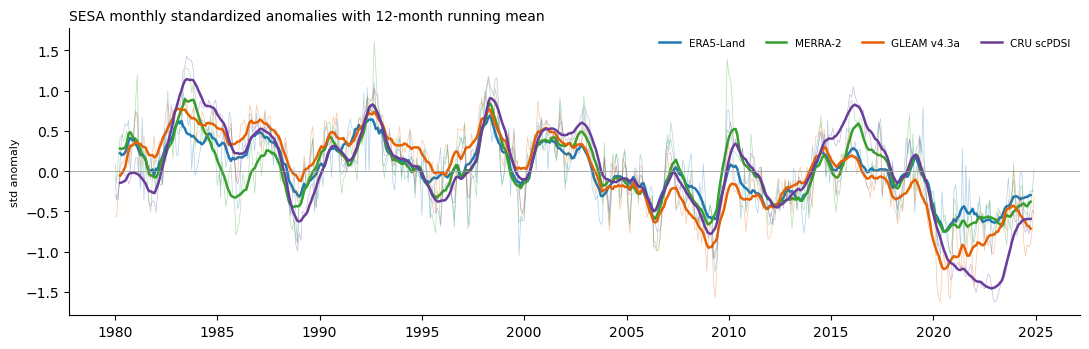

In [24]:
# monthly series with a 12-month running mean
fig, ax = plt.subplots(figsize=(11, 3.6))
for n in mon:
    ax.plot(mon.index, mon[n], color=COLORS.get(n), lw=0.5, alpha=0.35)
    ax.plot(mon.index, mon[n].rolling(12, center=True, min_periods=9).mean(), color=COLORS.get(n), lw=1.8, label=n)
ax.axhline(0, color="#999999", lw=0.6)
ax.set_ylabel("std anomaly", fontsize=8)
ax.legend(fontsize=7.5, frameon=False, ncol=4)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("SESA monthly standardized anomalies with 12-month running mean", fontsize=10, loc="left")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_monthly_series.png"), dpi=200, bbox_inches="tight")
plt.show()

## Figure 2: monthly standardized anomalies

In [27]:
def box_monthly_climatology(da, start_year, end_year, month_order):
    # SESA cos(lat)-weighted box mean -> monthly mean and std across years
    box = da.weighted(np.cos(np.deg2rad(da["lat"]))).mean(("lat", "lon"))
    box = box.sel(time=slice(f"{start_year}-01-01", f"{end_year}-12-31"))
    g = box.groupby("time.month")
    return g.mean("time").sel(month=month_order), g.std("time").sel(month=month_order)


def plot_climatology_sm_pdsi(data_dict, start_year, end_year, ref="",
                             sm_names=("ERA5-Land", "MERRA-2", "GLEAM v4.3a"), pdsi_name="CRU scPDSI",
                             colors=None, show_spread=True):
    # month_order = [9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]
    # month_labels = ['S', 'O', 'N', 'D', 'J', 'F', 'M', 'A', 'M', 'J', 'J', 'A']
    month_order = list(range(1, 13))
    month_labels = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']
    colors = colors or {"ERA5-Land": "#1f78b4", "MERRA-2": "#33a02c", "GLEAM v4.3a": "#e66101", "CRU scPDSI": "#6a3d9a"}
    markers = ["o", "s", "^", "d", "v"]
    x = np.arange(1, 13)

    fig, ax1 = plt.subplots(figsize=(12, 6))

    # Left axis: all soil-moisture datasets on one scale
    for k, name in enumerate(sm_names):
        mean, sd = box_monthly_climatology(data_dict[name], start_year, end_year, month_order)
        ax1.plot(x, mean.values, color=colors.get(name), marker=markers[k % len(markers)], lw=2, label=name)
        if show_spread:
            ax1.fill_between(x, (mean - sd).values, (mean + sd).values, color=colors.get(name), alpha=0.12, linewidth=0)
    ax1.set_xlabel('Months', fontsize=12)
    ax1.set_ylabel('Root-zone soil moisture (m³ m⁻³)', fontsize=12)
    ax1.set_xticks(x, month_labels)
    ax1.grid(axis="y", color="#dddddd", lw=0.6)

    # Right axis: PDSI
    ax2 = ax1.twinx()
    mean, sd = box_monthly_climatology(data_dict[pdsi_name], start_year, end_year, month_order)
    pdsi_color = colors.get(pdsi_name, "black")
    ax2.plot(x, mean.values, color=pdsi_color, marker="D", lw=2, ls="--", label=pdsi_name)
    if show_spread:
        ax2.fill_between(x, (mean - sd).values, (mean + sd).values, color=pdsi_color, alpha=0.10, linewidth=0)
    ax2.axhline(0, color=pdsi_color, ls=":", lw=1.2)
    lim = float(np.nanmax(np.abs((mean + sd).values if show_spread else mean.values))) * 1.1
    ax2.set_ylim(-lim, lim)                      # symmetric around 0
    ax2.set_ylabel('PDSI', color=pdsi_color, fontsize=12)
    ax2.tick_params(axis='y', labelcolor=pdsi_color)
    ax2.spines['right'].set_color(pdsi_color)

    # Combined legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    #ax1.legend(h1 + h2, l1 + l2, loc='upper right', frameon=False)
    ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.12),
               ncol=len(h1 + h2), frameon=False, fontsize=11)

    ax1.set_title(f'SESA monthly climatology {start_year}–{end_year} {ref}'.strip(), fontsize=14, fontweight='bold')
    fig.tight_layout()
    return fig

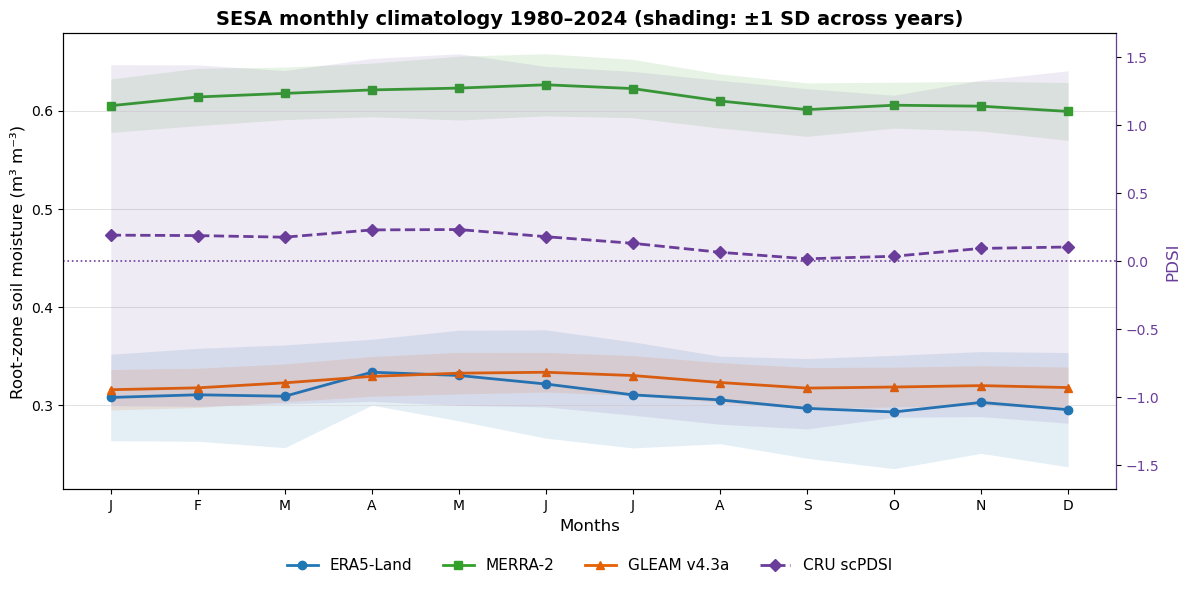

In [28]:
# (a) plot the climatology per variable
fig = plot_climatology_sm_pdsi(data, 1980, 2024, ref="(shading: ±1 SD across years)")
fig.savefig(os.path.join(FIG_DIR, "sesa_monthly_climatology.png"), dpi=200, bbox_inches="tight")
plt.show()

MERRA2 Wetter Overall over the area compared to ERA5 and GLEAM. Should we drop?

Recreate figure in this style:
https://zacklabe.com/wp-content/uploads/2026/07/noaa_monthly_rank.png

For the CMIP6 need to add the temp lines: 1deg, 1.5deg etc. Should probably add for the observations too to match the models. 

Add a line for the global temperatures on the top?? Hmmm. Add the global temp + temp over SESA. 

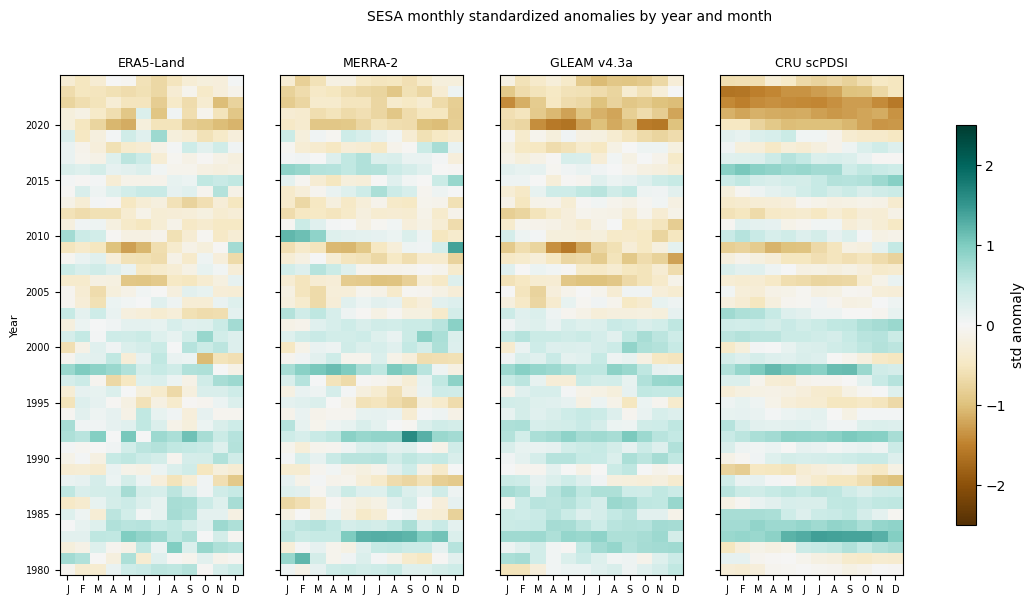

In [18]:
# (b) year x month heat maps, one per dataset
fig, axes = plt.subplots(1, len(mon.columns), figsize=(3.4 * len(mon.columns), 6.5), sharey=True)
for ax, n in zip(np.atleast_1d(axes), mon.columns):
    grid = mon[n].to_frame("z").assign(year=mon.index.year, month=mon.index.month).pivot(index="year", columns="month", values="z")
    im = ax.pcolormesh(np.arange(1, 13), grid.index, grid.values, cmap="BrBG", vmin=-2.5, vmax=2.5, shading="nearest")
    ax.set_xticks(range(1, 13), [m[0] for m in MONTHS], fontsize=7)
    ax.set_title(n, fontsize=9)
    ax.tick_params(labelsize=7)
np.atleast_1d(axes)[0].set_ylabel("Year", fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.8, label="std anomaly")
fig.suptitle("SESA monthly standardized anomalies by year and month", fontsize=10)
fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_monthly_heatmap.png"), dpi=200, bbox_inches="tight")
plt.show()

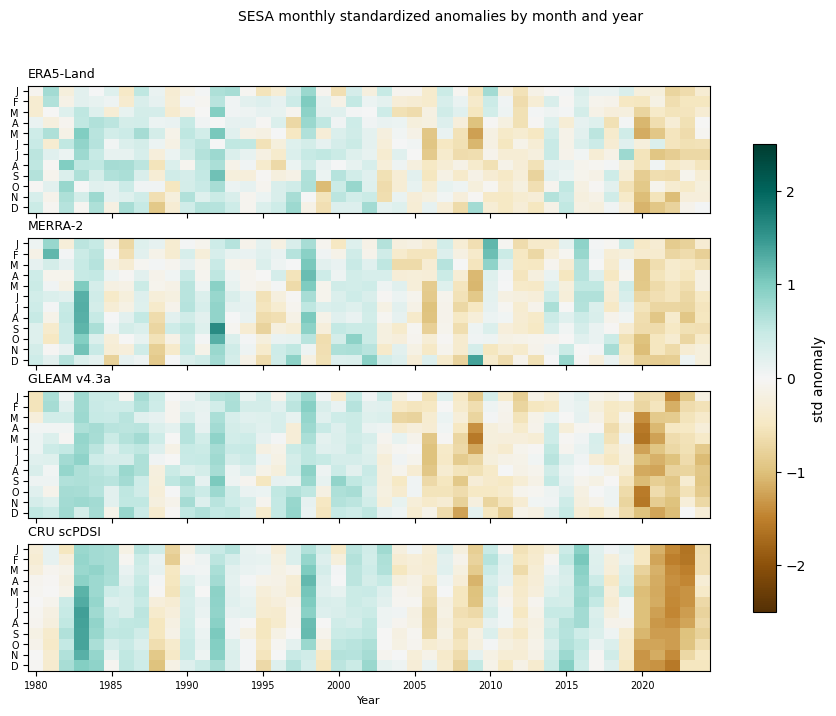

In [17]:
# (b) month x year heat maps, one per dataset
fig, axes = plt.subplots(len(mon.columns), 1, figsize=(11, 1.9 * len(mon.columns)), sharex=True)
for ax, n in zip(np.atleast_1d(axes), mon.columns):
    grid = mon[n].to_frame("z").assign(year=mon.index.year, month=mon.index.month).pivot(index="month", columns="year", values="z")
    im = ax.pcolormesh(grid.columns, np.arange(1, 13), grid.values, cmap="BrBG", vmin=-2.5, vmax=2.5, shading="nearest")
    ax.set_yticks(range(1, 13), [m[0] for m in MONTHS], fontsize=7)
    ax.invert_yaxis()                      # Jan at the top
    ax.set_title(n, fontsize=9, loc="left")
    ax.tick_params(labelsize=7)
np.atleast_1d(axes)[-1].set_xlabel("Year", fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.8, label="std anomaly")
fig.suptitle("SESA monthly standardized anomalies by month and year", fontsize=10)
fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_monthly_heatmap.png"), dpi=200, bbox_inches="tight")
plt.show()

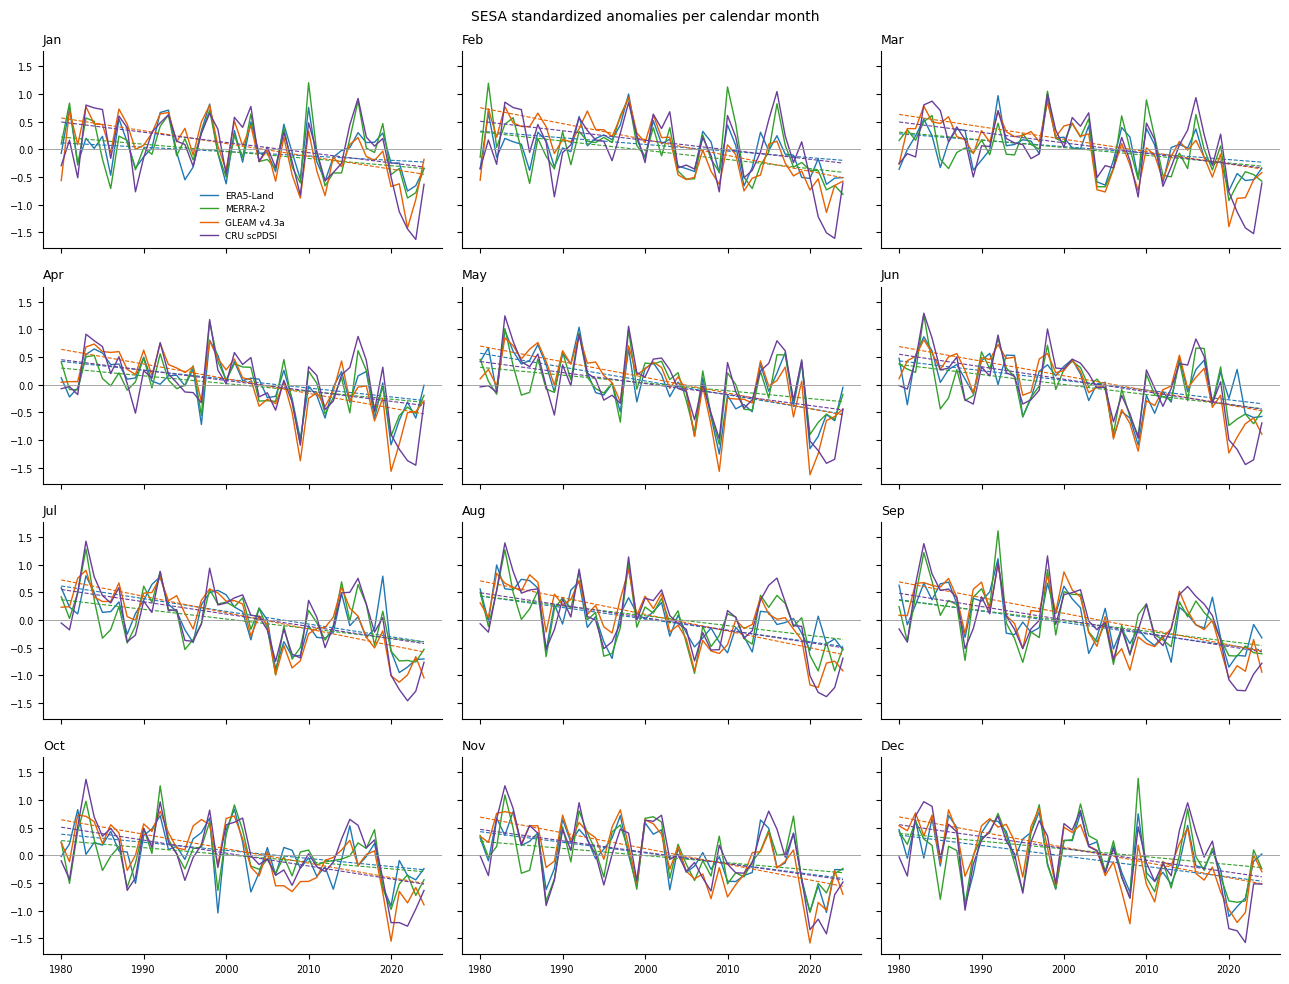

In [38]:
# (c) one panel per calendar month, with each dataset's Sen trend
mon_rows = []
fig, axes = plt.subplots(4, 3, figsize=(13, 10), sharex=True, sharey=True)
for k, ax in enumerate(axes.flat):
    sub = mon[mon.index.month == k + 1]
    t = sub.index.year.values.astype(float)
    for n in sub:
        sl, b, p = sen_trend(sub[n].values, t)
        mon_rows.append(dict(month=MONTHS[k], dataset=n, sen_per_decade=sl, p=p))
        ax.plot(t, sub[n], color=COLORS.get(n), lw=1.0, label=n)
        ax.plot(t, b + sl / 10 * t, color=COLORS.get(n), lw=0.8, ls="--")
    ax.axhline(0, color="#999999", lw=0.6)
    ax.set_title(MONTHS[k], fontsize=9, loc="left")
    ax.tick_params(labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)
axes.flat[0].legend(fontsize=6.5, frameon=False)
fig.suptitle("SESA standardized anomalies per calendar month", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_per_month.png"), dpi=200, bbox_inches="tight")
plt.show()

mon_trends = pd.DataFrame(mon_rows)
#mon_trends.to_csv(os.path.join(OUT_DIR, "sesa_std_anom_monthly_trends.csv"), index=False)

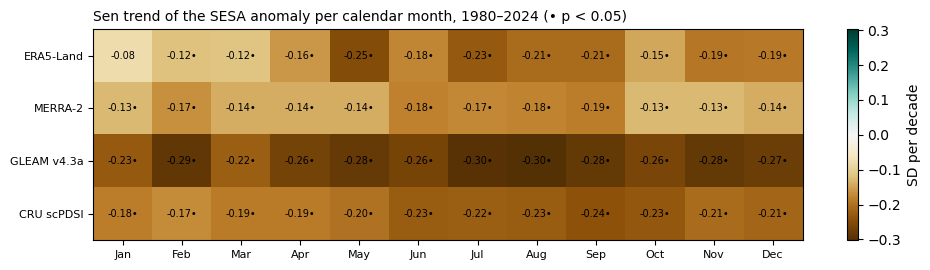

In [39]:
# (d) monthly Sen trends: dataset x calendar month (dots: p < 0.05)
tr = mon_trends.pivot(index="dataset", columns="month", values="sen_per_decade")[MONTHS].reindex(list(mon.columns))
pv = mon_trends.pivot(index="dataset", columns="month", values="p")[MONTHS].reindex(list(mon.columns))
vmax = np.nanmax(np.abs(tr.values))
fig, ax = plt.subplots(figsize=(10, 2.8))
im = ax.imshow(tr.values, cmap="BrBG", vmin=-vmax, vmax=vmax, aspect="auto")
for i in range(tr.shape[0]):
    for j in range(tr.shape[1]):
        ax.text(j, i, f"{tr.values[i, j]:+.2f}" + ("•" if pv.values[i, j] < 0.05 else ""), ha="center", va="center", fontsize=7)
ax.set_xticks(range(12), MONTHS, fontsize=8)
ax.set_yticks(range(len(tr)), tr.index, fontsize=8)
fig.colorbar(im, ax=ax, label="SD per decade")
ax.set_title(f"Sen trend of the SESA anomaly per calendar month, {YEARS[0]}–{YEARS[1]} (• p < 0.05)", fontsize=10, loc="left")
fig.tight_layout()
#fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_monthly_trends.png"), dpi=200, bbox_inches="tight")
plt.show()

## Figure 3: histograms – has the distribution shifted?
Box-mean standardized anomalies in the early (1980–2001) and late (2002–2024) halves (set by `YEARS` and `SPLIT_YEAR`). Each panel gives the change in mean and the two-sample Kolmogorov–Smirnov p-value. Values are serially correlated (especially monthly soil moisture), so the KS p-values are optimistic.

Can probably ignore this.

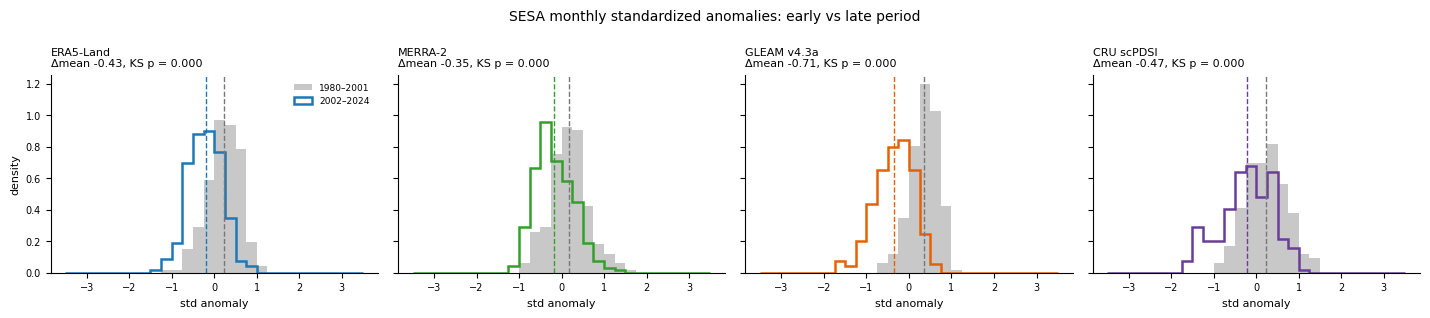

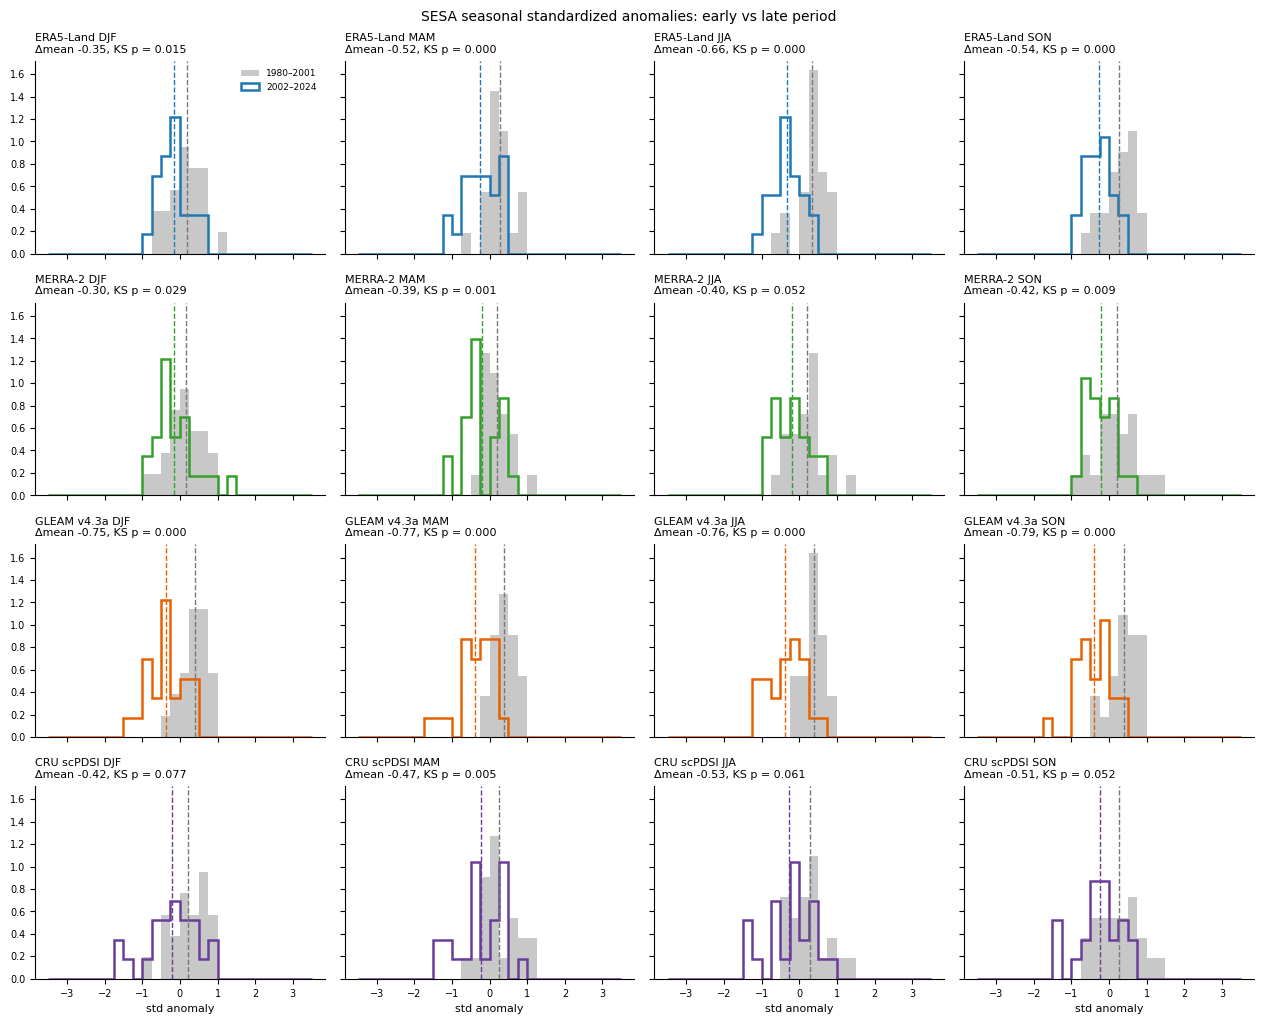

n_early  n_late  mean_early  mean_late  \
period  dataset                                               
monthly ERA5-Land        264     276       0.222     -0.205   
        MERRA-2          264     276       0.178     -0.170   
        GLEAM v4.3a      264     276       0.365     -0.349   
        CRU scPDSI       264     276       0.238     -0.228   
DJF     ERA5-Land         21      23       0.183     -0.167   
MAM     ERA5-Land         22      23       0.267     -0.255   
JJA     ERA5-Land         22      23       0.335     -0.321   
SON     ERA5-Land         22      23       0.277     -0.265   
DJF     MERRA-2           21      23       0.158     -0.144   
MAM     MERRA-2           22      23       0.202     -0.193   
JJA     MERRA-2           22      23       0.205     -0.196   
SON     MERRA-2           22      23       0.213     -0.203   
DJF     GLEAM v4.3a       21      23       0.392     -0.358   
MAM     GLEAM v4.3a       22      23       0.391     -0.374   
JJA     GLEAM v4.3a       22      23       0.389     -0.372   
SON     GLEAM v4.3a       22      23       0.404     -0.386   
DJF     CRU scPDSI        21      23       0.218     -0.199   
MAM     CRU scPDSI        22      23       0.241     -0.230   
JJA     CRU scPDSI        22      23       0.272     -0.260   
SON     CRU scPDSI        22      23       0.259     -0.248   

                     frac_below_m1_early  frac_below_m1_late  \
period  dataset                                                
monthly ERA5-Land                  0.004               0.025   
        MERRA-2                    0.000               0.011   
        GLEAM v4.3a                0.000               0.080   
        CRU scPDSI                 0.000               0.141   
DJF     ERA5-Land                  0.000               0.000   
MAM     ERA5-Land                  0.000               0.087   
JJA     ERA5-Land                  0.000               0.043   
SON     ERA5-Land                  0.000               0.000   
DJF     MERRA-2                    0.000               0.000   
MAM     MERRA-2                    0.000               0.087   
JJA     MERRA-2                    0.000               0.000   
SON     MERRA-2                    0.000               0.000   
DJF     GLEAM v4.3a                0.000               0.087   
MAM     GLEAM v4.3a                0.000               0.130   
JJA     GLEAM v4.3a                0.000               0.130   
SON     GLEAM v4.3a                0.000               0.043   
DJF     CRU scPDSI                 0.000               0.130   
MAM     CRU scPDSI                 0.000               0.174   
JJA     CRU scPDSI                 0.000               0.174   
SON     CRU scPDSI                 0.000               0.130   

                     frac_above_p1_early  frac_above_p1_late   ks_p  
period  dataset                                                      
monthly ERA5-Land                  0.011               0.000  0.000  
        MERRA-2                    0.049               0.011  0.000  
        GLEAM v4.3a                0.004               0.000  0.000  
        CRU scPDSI                 0.053               0.004  0.000  
DJF     ERA5-Land                  0.048               0.000  0.015  
MAM     ERA5-Land                  0.000               0.000  0.000  
JJA     ERA5-Land                  0.000               0.000  0.000  
SON     ERA5-Land                  0.000               0.000  0.000  
DJF     MERRA-2                    0.000               0.043  0.029  
MAM     MERRA-2                    0.045               0.000  0.001  
JJA     MERRA-2                    0.045               0.000  0.052  
SON     MERRA-2                    0.091               0.000  0.009  
DJF     GLEAM v4.3a                0.000               0.000  0.000  
MAM     GLEAM v4.3a                0.000               0.000  0.000  
JJA     GLEAM v4.3a                0.000               0.000  0.000  
SON     GLEAM v4.3a                

In [41]:
early = lambda idx: idx < SPLIT_YEAR
bins = np.linspace(-3.5, 3.5, 29)


def hist_panel(ax, x, is_early, color, title):
    a, b = x[is_early].dropna(), x[~is_early].dropna()
    ax.hist(a, bins=bins, density=True, color="#bbbbbb", alpha=0.8, label=f"{YEARS[0]}–{SPLIT_YEAR - 1}")
    ax.hist(b, bins=bins, density=True, histtype="step", color=color, lw=1.8, label=f"{SPLIT_YEAR}–{YEARS[1]}")
    ax.axvline(a.mean(), color="#777777", lw=1, ls="--")
    ax.axvline(b.mean(), color=color, lw=1, ls="--")
    p = stats.ks_2samp(a, b).pvalue if len(a) > 2 and len(b) > 2 else np.nan
    ax.set_title(f"{title}\nΔmean {b.mean() - a.mean():+.2f}, KS p = {p:.3f}", fontsize=8, loc="left")
    ax.tick_params(labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)
    return dict(n_early=len(a), n_late=len(b), mean_early=a.mean(), mean_late=b.mean(),
                frac_below_m1_early=(a < -1).mean(), frac_below_m1_late=(b < -1).mean(),
                frac_above_p1_early=(a > 1).mean(), frac_above_p1_late=(b > 1).mean(), ks_p=p)


# (a) monthly anomalies, one panel per dataset
hist_rows = []
fig, axes = plt.subplots(1, len(mon.columns), figsize=(3.6 * len(mon.columns), 3.2), sharey=True)
for ax, n in zip(np.atleast_1d(axes), mon.columns):
    st = hist_panel(ax, mon[n], early(mon.index.year), COLORS.get(n), n)
    hist_rows.append(dict(period="monthly", dataset=n, **st))
    ax.set_xlabel("std anomaly", fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("density", fontsize=8)
np.atleast_1d(axes)[0].legend(fontsize=6.5, frameon=False)
fig.suptitle("SESA monthly standardized anomalies: early vs late period", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_hist_monthly.png"), dpi=200, bbox_inches="tight")
plt.show()

# (b) seasonal anomalies, datasets x seasons
names = list(mon.columns)
fig, axes = plt.subplots(len(names), len(SEASONS), figsize=(3.2 * len(SEASONS), 2.6 * len(names)), sharex=True, sharey=True)
for i, n in enumerate(names):
    for j, s in enumerate(SEASONS):
        x = seas[s][n]
        st = hist_panel(axes[i, j], x, early(x.index.values), COLORS.get(n), f"{n} {s}")
        hist_rows.append(dict(period=s, dataset=n, **st))
for ax in axes[-1]:
    ax.set_xlabel("std anomaly", fontsize=8)
axes[0, 0].legend(fontsize=6.5, frameon=False)
fig.suptitle("SESA seasonal standardized anomalies: early vs late period", fontsize=10)
fig.tight_layout()
#fig.savefig(os.path.join(FIG_DIR, "sesa_std_anom_hist_seasonal.png"), dpi=200, bbox_inches="tight")
plt.show()

hist_stats = pd.DataFrame(hist_rows).set_index(["period", "dataset"])
#hist_stats.to_csv(os.path.join(OUT_DIR, "sesa_std_anom_hist_stats.csv"))
hist_stats.round(3)

## Where is the wet → dry reversal largest?
Per grid cell and dataset (FYI: over a wider window than the SESA box so the pattern around it is visible):
1. All datasets on a common 0.5° grid, `REV_SEASON` means (default annual), standardized against `REF_PERIOD`.
2. Continuous two-segment (hinge) trend $z = a + b_1 t + b_2 (t - t_b)_+$, breakpoint $t_b$ by grid search with at least `REV_MIN_SEG` years per segment.
3. **Wet → dry** = pre-break slope > 0 and post-break slope < 0. **Reversal size** = pre − post slope (SD per decade): how sharply wetting turned into drying.
4. **Significance (dots):** the hinge's F statistic against a single straight line, compared with a 95% critical value from Monte Carlo AR(1) noise with the cell's own lag-1 autocorrelation (this allows for the breakpoint search and for persistence).
5. **Agreement:** how many datasets show a wet → dry reversal in each cell, the mean reversal size, and the median break year.

In [30]:
REV_REGION = dict(lat=(-56.0, 8.0), lon=(-82.0, -34.0))   # map window
REV_SEASON = "ANN"            # "ANN" (calendar year) or "DJF", "MAM", "JJA", "SON"
REV_MIN_SEG = 10              # minimum years per segment
REV_GRID = 0.5                # common grid (deg)
REV_NSIM = 2000               # Monte Carlo draws per AR(1) value
REV_ALPHA = 0.05
REV_MIN_AGREE = 3             # datasets that must agree for the agreement maps
rev_rng = np.random.default_rng(42)

In [31]:
def annual(da):
    year = da["time"].dt.year.rename("year")
    return da.groupby(year).mean("time").where(da.notnull().groupby(year).sum("time") == 12)


def hinge_fit(t, Y, min_seg):
    # y = a + b1 t + b2 (t - tb)+ for every candidate tb, all columns of Y at once
    t = np.asarray(t, float)
    tc = t - t.mean()
    Xl = np.column_stack([np.ones_like(t), tc])
    bl, *_ = np.linalg.lstsq(Xl, Y, rcond=None)
    rss_lin = ((Y - Xl @ bl) ** 2).sum(0)
    best = np.full(Y.shape[1], np.inf)
    tb_best, b1_best, b2_best = (np.full(Y.shape[1], np.nan) for _ in range(3))
    for tb in t[min_seg - 1: len(t) - min_seg + 1]:
        X = np.column_stack([np.ones_like(t), tc, np.maximum(t - tb, 0)])
        b, *_ = np.linalg.lstsq(X, Y, rcond=None)
        rss = ((Y - X @ b) ** 2).sum(0)
        better = rss < best
        best[better], tb_best[better] = rss[better], tb
        b1_best[better], b2_best[better] = b[1, better], b[2, better]
    F = (rss_lin - best) / (best / (len(t) - 4))
    resid = Y - Xl @ bl
    phi = np.clip((resid[:-1] * resid[1:]).sum(0) / (resid ** 2).sum(0), 0, 0.9)
    return dict(tb=tb_best, pre=b1_best, post=b1_best + b2_best, F=F, phi=phi)


def null_critical(t, min_seg, phis=np.arange(0, 0.91, 0.1), nsim=REV_NSIM, alpha=REV_ALPHA):
    # 95% critical F for the hinge-vs-line test under AR(1) noise (F does not depend on a linear trend)
    n, crit = len(t), []
    for phi in phis:
        e = np.empty((n, nsim))
        e[0] = rev_rng.normal(size=nsim)
        for k in range(1, n):
            e[k] = phi * e[k - 1] + np.sqrt(1 - phi ** 2) * rev_rng.normal(size=nsim)
        crit.append(np.percentile(hinge_fit(t, e, min_seg)["F"], 100 * (1 - alpha)))
    return phis, np.array(crit)

In [ ]:
# 1) fields on a common grid
fields = {}
for name, cfg in DATASETS.items():
    da = load_dataset(name, cfg, REV_REGION)
    step = float(np.abs(np.diff(da["lat"].values)).mean())
    f = int(round(REV_GRID / step))
    if f > 1:
        da = da.coarsen(lat=f, lon=f, boundary="trim").mean()
    x = annual(da) if REV_SEASON == "ANN" else seasonal(da, REV_SEASON)
    fields[name] = std_anom_seasonal(x.sel(year=slice(*YEARS)))
template = fields["CRU scPDSI"]
for name in fields:
    fields[name] = fields[name].reindex(lat=template["lat"], lon=template["lon"], method="nearest", tolerance=0.3 * REV_GRID)
rev = xr.concat(list(xr.align(*fields.values(), join="inner")), dim=pd.Index(list(fields), name="dataset"))
rev = rev.dropna("year", how="all")
yrs = rev["year"].values.astype(float)
print(dict(rev.sizes), "| years", int(yrs[0]), "-", int(yrs[-1]))

ERA5-Land: could not read /home/andish/data/ERA5-Land_Update_Oct_2026.grib (RuntimeError: Cannot find the ecCodes library); using /home/andish/data/sm/ERA5_ROOT.nc
{'dataset': 4, 'year': 45, 'lat': 128, 'lon': 96} | years 1980 - 2024


In [34]:
# 2) hinge fits per dataset
phis, crit = null_critical(yrs, REV_MIN_SEG)
out = {k: np.full((rev.sizes["dataset"], rev.sizes["lat"] * rev.sizes["lon"]), np.nan)
       for k in ["tb", "pre", "post", "F", "phi", "Fcrit"]}
for i, name in enumerate(rev["dataset"].values):
    Y = rev.sel(dataset=name).transpose("year", "lat", "lon").values.reshape(len(yrs), -1)
    ok = np.isfinite(Y).all(0)
    h = hinge_fit(yrs, Y[:, ok], REV_MIN_SEG)
    for k in ["tb", "pre", "post", "F", "phi"]:
        out[k][i, ok] = h[k]
    out["Fcrit"][i, ok] = np.interp(h["phi"], phis, crit)

shape = (rev.sizes["dataset"], rev.sizes["lat"], rev.sizes["lon"])
coords = dict(dataset=rev["dataset"], lat=rev["lat"], lon=rev["lon"])
R = xr.Dataset({k: (("dataset", "lat", "lon"), v.reshape(shape)) for k, v in out.items()}, coords=coords)
R["pre"], R["post"] = R["pre"] * 10, R["post"] * 10                       # SD per decade
R["wet_to_dry"] = (R["pre"] > 0) & (R["post"] < 0)
R["significant"] = R["F"] > R["Fcrit"]
R["reversal_size"] = (R["pre"] - R["post"]).where(R["wet_to_dry"])     # SD per decade
R["break_year"] = R["tb"].where(R["wet_to_dry"])

# 3) agreement across datasets
land = R["pre"].notnull()
R["n_wet_to_dry"] = R["wet_to_dry"].where(land).sum("dataset").where(land.any("dataset"))
R["n_wet_to_dry_sig"] = (R["wet_to_dry"] & R["significant"]).where(land).sum("dataset").where(land.any("dataset"))
agree = R["n_wet_to_dry"] >= REV_MIN_AGREE
R["mean_reversal_size"] = R["reversal_size"].mean("dataset").where(agree)
R["median_break_year"] = R["break_year"].median("dataset").where(agree)
R.attrs.update(season=REV_SEASON, years=f"{int(yrs[0])}-{int(yrs[-1])}", min_seg=REV_MIN_SEG, units="SD per decade")
R.drop_vars(["wet_to_dry", "significant"]).to_netcdf(os.path.join(OUT_DIR, f"sesa_reversal_maps_{REV_SEASON}.nc"))

for name in R["dataset"].values:
    r = R.sel(dataset=name)
    n = int(r["pre"].notnull().sum())
    print(f"{name:12s} wet→dry in {float(r['wet_to_dry'].sum()) / n:5.1%} of cells, "
          f"significant {float((r['wet_to_dry'] & r['significant']).sum()) / n:5.1%}")

ERA5-Land    wet→dry in 32.9% of cells, significant  6.4%
MERRA-2      wet→dry in 44.1% of cells, significant  7.0%
GLEAM v4.3a  wet→dry in 42.2% of cells, significant 10.9%
CRU scPDSI   wet→dry in 47.2% of cells, significant  5.3%


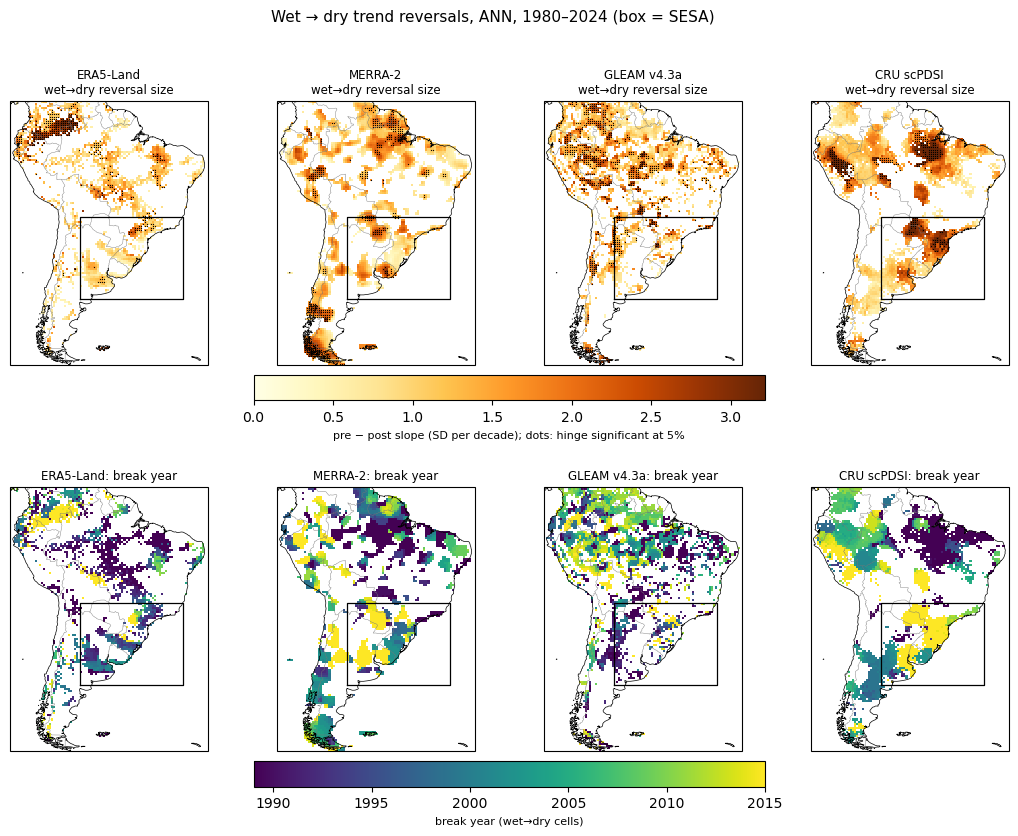

In [35]:
def rev_ax(fig, pos):
    ax = fig.add_subplot(*pos, projection=ccrs.PlateCarree())
    ax.set_extent([REV_REGION["lon"][0], REV_REGION["lon"][1], REV_REGION["lat"][0], REV_REGION["lat"][1]], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor="#777777")
    (la0, la1), (lo0, lo1) = REGION["lat"], REGION["lon"]
    ax.plot([lo0, lo1, lo1, lo0, lo0], [la0, la0, la1, la1, la0], color="k", lw=0.9, transform=ccrs.PlateCarree())
    return ax


def dots(ax, mask):
    yy, xx = np.meshgrid(R["lat"].values, R["lon"].values, indexing="ij")
    m = np.asarray(mask, bool)
    ax.scatter(xx[m], yy[m], s=0.8, c="k", linewidths=0, transform=ccrs.PlateCarree())


size_max = float(np.nanpercentile(R["reversal_size"], 98))
names = list(R["dataset"].values)
fig = plt.figure(figsize=(3.3 * len(names), 9.2))
for j, name in enumerate(names):
    r = R.sel(dataset=name)
    ax = rev_ax(fig, (2, len(names), j + 1))
    pc1 = ax.pcolormesh(R["lon"], R["lat"], r["reversal_size"], cmap="YlOrBr", vmin=0, vmax=size_max,
                        shading="nearest", transform=ccrs.PlateCarree())
    dots(ax, r["wet_to_dry"] & r["significant"])
    ax.set_title(f"{name}\nwet→dry reversal size", fontsize=8.5)
    ax = rev_ax(fig, (2, len(names), len(names) + j + 1))
    pc2 = ax.pcolormesh(R["lon"], R["lat"], r["break_year"], cmap="viridis",
                        vmin=yrs[REV_MIN_SEG - 1], vmax=yrs[-REV_MIN_SEG], shading="nearest", transform=ccrs.PlateCarree())
    ax.set_title(f"{name}: break year", fontsize=8.5)
cb1 = fig.colorbar(pc1, ax=fig.axes[0::2], orientation="horizontal", shrink=0.5, pad=0.03)
cb1.set_label("pre − post slope (SD per decade); dots: hinge significant at 5%", fontsize=8)
cb2 = fig.colorbar(pc2, ax=fig.axes[1::2], orientation="horizontal", shrink=0.5, pad=0.03)
cb2.set_label("break year (wet→dry cells)", fontsize=8)
fig.suptitle(f"Wet → dry trend reversals, {REV_SEASON}, {int(yrs[0])}–{int(yrs[-1])} (box = SESA)", fontsize=11)
fig.savefig(os.path.join(FIG_DIR, f"sesa_reversal_maps_by_dataset_{REV_SEASON}.png"), dpi=200, bbox_inches="tight")
plt.show()

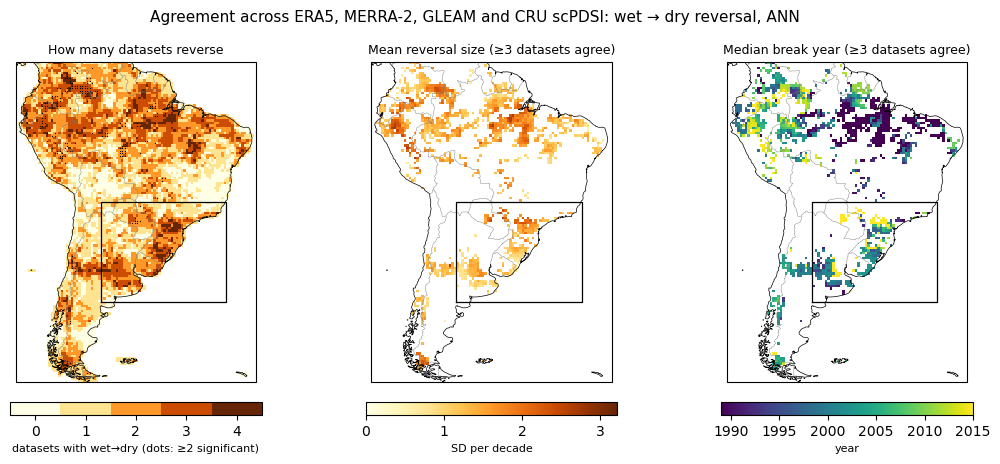

,,mean_reversal_size,median_break_year,n_wet_to_dry,n_wet_to_dry_sig,size_CRU scPDSI,size_ERA5-Land,size_GLEAM v4.3a,size_MERRA-2
lat,lon,,,,,,,,
-5.25,-77.25,2.74,2014.0,3.0,2.0,3.30,2.66,NaN,2.27
-9.25,-74.75,2.68,2015.0,3.0,2.0,3.27,NaN,2.70,2.06
-3.25,-54.25,2.67,1989.0,3.0,1.0,3.59,NaN,2.39,2.02
-11.25,-73.25,2.67,2014.0,3.0,3.0,3.10,NaN,2.20,2.70
-4.75,-77.25,2.66,2014.0,3.0,2.0,3.30,NaN,2.42,2.24
-5.25,-77.75,2.63,2014.0,3.0,1.0,2.86,3.26,NaN,1.76
-32.75,-66.25,2.63,2015.0,3.0,1.0,NaN,3.51,1.88,2.48
-4.75,-57.75,2.62,1989.0,3.0,2.0,NaN,1.81,3.76,2.27
-3.75,-54.25,2.61,1989.0,3.0,0.0,3.45,NaN,2.64,1.75


In [37]:
fig = plt.figure(figsize=(13, 5.2))
ax = rev_ax(fig, (1, 3, 1))
cmap_n = plt.get_cmap("YlOrBr", len(names) + 1)
pc = ax.pcolormesh(R["lon"], R["lat"], R["n_wet_to_dry"], cmap=cmap_n, vmin=-0.5, vmax=len(names) + 0.5,
                   shading="nearest", transform=ccrs.PlateCarree())
dots(ax, R["n_wet_to_dry_sig"] >= 2)
fig.colorbar(pc, ax=ax, orientation="horizontal", shrink=0.85, pad=0.05, ticks=range(len(names) + 1)).set_label(
    "datasets with wet→dry (dots: ≥2 significant)", fontsize=8)
ax.set_title("How many datasets reverse", fontsize=9)

ax = rev_ax(fig, (1, 3, 2))
pc = ax.pcolormesh(R["lon"], R["lat"], R["mean_reversal_size"], cmap="YlOrBr", vmin=0, vmax=size_max,
                   shading="nearest", transform=ccrs.PlateCarree())
fig.colorbar(pc, ax=ax, orientation="horizontal", shrink=0.85, pad=0.05).set_label("SD per decade", fontsize=8)
ax.set_title(f"Mean reversal size (≥{REV_MIN_AGREE} datasets agree)", fontsize=9)

ax = rev_ax(fig, (1, 3, 3))
pc = ax.pcolormesh(R["lon"], R["lat"], R["median_break_year"], cmap="viridis",
                   vmin=yrs[REV_MIN_SEG - 1], vmax=yrs[-REV_MIN_SEG], shading="nearest", transform=ccrs.PlateCarree())
fig.colorbar(pc, ax=ax, orientation="horizontal", shrink=0.85, pad=0.05).set_label("year", fontsize=8)
ax.set_title(f"Median break year (≥{REV_MIN_AGREE} datasets agree)", fontsize=9)

fig.suptitle(f"Agreement across ERA5, MERRA-2, GLEAM and CRU scPDSI: wet → dry reversal, {REV_SEASON}", fontsize=11)
fig.savefig(os.path.join(FIG_DIR, f"sesa_reversal_agreement_{REV_SEASON}.png"), dpi=200, bbox_inches="tight")
plt.show()

# hotspots: cells where >= REV_MIN_AGREE datasets reverse, ranked by mean reversal size
hot = R[["mean_reversal_size", "median_break_year", "n_wet_to_dry", "n_wet_to_dry_sig"]].to_dataframe().dropna()
sizes = R["reversal_size"].to_dataframe().reset_index().pivot_table(index=["lat", "lon"], columns="dataset", values="reversal_size")
hot = hot.join(sizes.add_prefix("size_")).sort_values("mean_reversal_size", ascending=False)
hot.to_csv(os.path.join(OUT_DIR, f"sesa_reversal_hotspots_{REV_SEASON}.csv"))
hot.head(20).round(2)

# Figure 4: STD Drops

* Abrupt wet -> dry changes: drops of >= 2 SD / >= 3 SD between
* consecutive seasons (each transition separately) and consecutive months

In [49]:
THRESHOLDS = [1, 2, 3]           # size of the drop in SD (can change later)
RESTANDARDIZE = True          # re-standardize the box-mean series (area averaging shrinks its SD below 1)
MIN_AGREE = 2                 # datasets that must flag the same step for it to count as a shared event

SEASON_MID = {"DJF": 1, "MAM": 4, "JJA": 7, "SON": 10}       # month used to place each season in time
PREV = {"DJF": "SON", "MAM": "DJF", "JJA": "MAM", "SON": "JJA"}
TRANSITIONS = [f"{PREV[s]}→{s}" for s in SEASONS]            # SON→DJF, DJF→MAM, MAM→JJA, JJA→SON
names = list(mon.columns)


In [50]:
def restd(df):
    return (df - df.mean()) / df.std(ddof=0)


def find_drops(dz, z, label_col):
    # one row per dataset and time step where the anomaly fell by >= min(THRESHOLDS)
    rows = []
    for n in names:
        hit = dz[n] <= -min(THRESHOLDS)
        for t in dz.index[hit.fillna(False).values]:
            rows.append(dict(time=t, dataset=n, step=label_col.loc[t],
                             z_before=z[n].shift(1).loc[t], z_after=z[n].loc[t], drop=dz.loc[t, n],
                             level=f"≤−{max(th for th in THRESHOLDS if dz.loc[t, n] <= -th)} SD"))
    return pd.DataFrame(rows).sort_values(["time", "dataset"]).reset_index(drop=True) if rows else pd.DataFrame(
        columns=["time", "dataset", "step", "z_before", "z_after", "drop", "level"])


def count_table(events, steps, step_name):
    # number of drops per step (transition or month), dataset and threshold
    out = {}
    for th in THRESHOLDS:
        e = events[events["drop"] <= -th]
        out[f"≤−{th} SD"] = (e.groupby(["step", "dataset"]).size().unstack("dataset")
                             .reindex(index=steps, columns=names).fillna(0).astype(int))
    tab = pd.concat(out, axis=1)
    tab.index.name = step_name
    return tab


def shared_events(events, th):
    # steps flagged by at least MIN_AGREE datasets
    e = events[events["drop"] <= -th]
    g = e.groupby("time").agg(step=("step", "first"), n_datasets=("dataset", "nunique"),
                              datasets=("dataset", lambda d: ", ".join(sorted(d))), mean_drop=("drop", "mean"))
    return g[g["n_datasets"] >= MIN_AGREE]

In [51]:
# ======================= 1) season to season ======================
frames = []
for s, df in seas.items():
    d = (restd(df) if RESTANDARDIZE else df).copy()
    d.index = pd.to_datetime([f"{y}-{SEASON_MID[s]:02d}-01" for y in df.index])
    frames.append(d.assign(step=f"{PREV[s]}→{s}"))
zs = pd.concat(frames).sort_index()                 # continuous series: ... SON, DJF, MAM, JJA, SON ...

mi = zs.index.year * 12 + zs.index.month
consecutive = np.r_[False, np.diff(mi) == 3]        # only compare neighbouring seasons
dz_seas = zs[names].diff()
dz_seas[~consecutive] = np.nan

seas_events = find_drops(dz_seas, zs[names], zs["step"])
seas_counts = count_table(seas_events, TRANSITIONS, "transition")
seas_events.to_csv(os.path.join(OUT_DIR, "sesa_abrupt_drops_seasonal_events.csv"), index=False)
seas_counts.to_csv(os.path.join(OUT_DIR, "sesa_abrupt_drops_seasonal_counts.csv"))
print("Season-to-season drops (counts per transition)")
display(seas_counts)
for th in THRESHOLDS:
    print(f"\nShared seasonal drops ≤−{th} SD (≥{MIN_AGREE} datasets)")
    display(shared_events(seas_events, th).round(2))

Season-to-season drops (counts per transition)


≤−1 SD                                   ≤−2 SD          \
dataset    ERA5-Land MERRA-2 GLEAM v4.3a CRU scPDSI ERA5-Land MERRA-2   
transition                                                              
SON→DJF            3       7           1          0         0       0   
DJF→MAM            5       4           2          0         1       0   
MAM→JJA            4       3           1          0         0       0   
JJA→SON            1       2           0          0         0       0   

                                     ≤−3 SD                                 
dataset    GLEAM v4.3a CRU scPDSI ERA5-Land MERRA-2 GLEAM v4.3a CRU scPDSI  
transition                                                                  
SON→DJF              0          0         0       0           0          0  
DJF→MAM              0          0         0       0           0          0  
MAM→JJA              0          0         0       0           0          0  
JJA→SON              0          0         0       0           0          0


Shared seasonal drops ≤−1 SD (≥2 datasets)


,step,n_datasets,datasets,mean_drop
time,,,,
1981-04-01,DJF→MAM,2,"ERA5-Land, MERRA-2",-1.60
1984-01-01,SON→DJF,2,"ERA5-Land, MERRA-2",-1.52
1986-01-01,SON→DJF,2,"ERA5-Land, MERRA-2",-1.41
1996-07-01,MAM→JJA,2,"ERA5-Land, MERRA-2",-1.27
1997-04-01,DJF→MAM,3,"ERA5-Land, GLEAM v4.3a, MERRA-2",-1.96
1999-10-01,JJA→SON,2,"ERA5-Land, MERRA-2",-1.25
2007-07-01,MAM→JJA,2,"ERA5-Land, MERRA-2",-1.41
2010-04-01,DJF→MAM,2,"ERA5-Land, MERRA-2",-1.57
2020-04-01,DJF→MAM,3,"ERA5-Land, GLEAM v4.3a, MERRA-2",-1.60



Shared seasonal drops ≤−2 SD (≥2 datasets)


,step,n_datasets,datasets,mean_drop
time,,,,



Shared seasonal drops ≤−3 SD (≥2 datasets)


,step,n_datasets,datasets,mean_drop
time,,,,


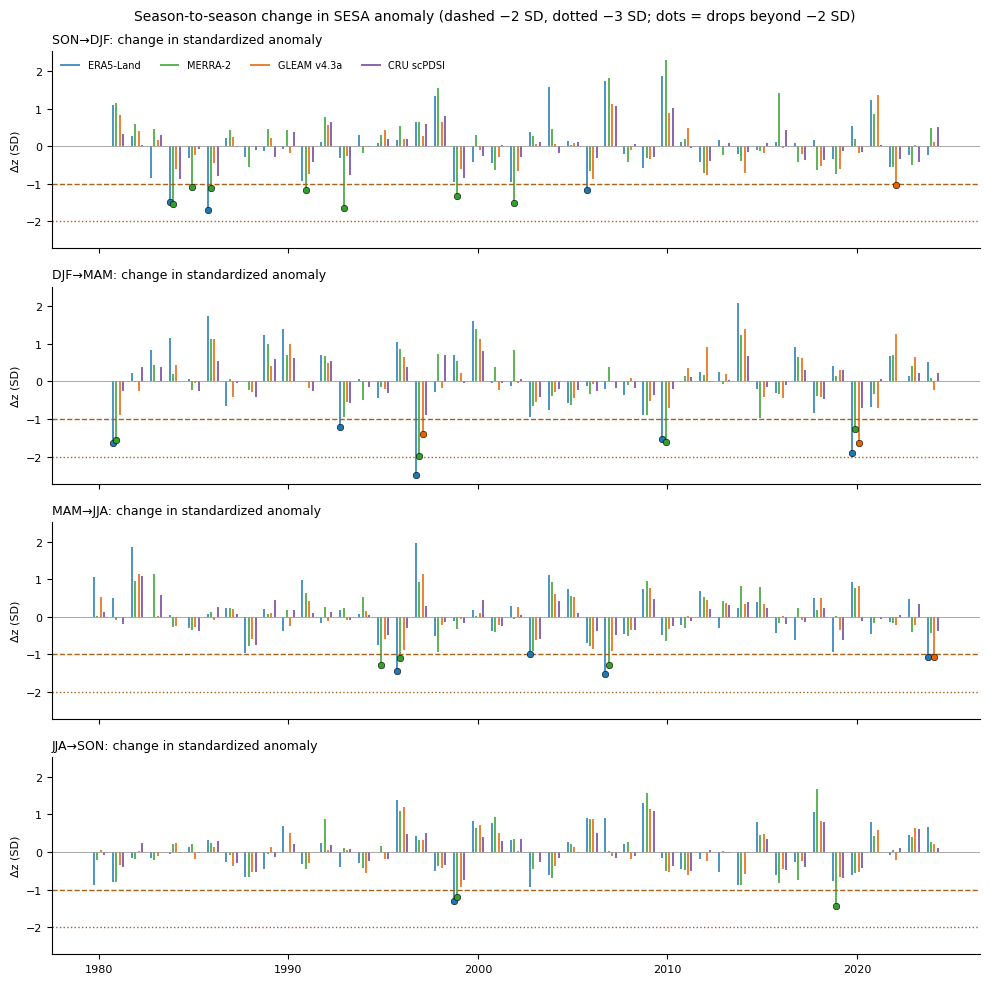

In [52]:
# figure: one panel per transition, change in anomaly by year
fig, axes = plt.subplots(len(TRANSITIONS), 1, figsize=(10, 2.5 * len(TRANSITIONS)), sharex=True, sharey=True)
for ax, tr in zip(np.atleast_1d(axes), TRANSITIONS):
    sub = dz_seas[zs["step"] == tr]
    yr = sub.index.year
    for k, n in enumerate(names):
        off = (k - (len(names) - 1) / 2) * 0.18                     # small offset so markers don't overlap
        ax.vlines(yr + off, 0, sub[n], color=COLORS.get(n), lw=1.4, alpha=0.8, label=n)
        big = sub[n] <= -min(THRESHOLDS)
        ax.scatter(yr[big] + off, sub[n][big], color=COLORS.get(n), s=22, zorder=3, edgecolors="k", linewidths=0.4)
    for th, ls in zip(THRESHOLDS, ["--", ":"]):
        ax.axhline(-th, color="#a6611a", lw=1, ls=ls)
    ax.axhline(0, color="#999999", lw=0.6)
    ax.set_title(f"{tr}: change in standardized anomaly", fontsize=9, loc="left")
    ax.set_ylabel("Δz (SD)", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
np.atleast_1d(axes)[0].legend(fontsize=7, frameon=False, ncol=len(names), loc="upper left")
fig.suptitle("Season-to-season change in SESA anomaly (dashed −2 SD, dotted −3 SD; dots = drops beyond −2 SD)", fontsize=10)
fig.tight_layout()
#fig.savefig(os.path.join(FIG_DIR, "sesa_abrupt_drops_seasonal.png"), dpi=200, bbox_inches="tight")
plt.show()


Month-to-month drops (counts per month step)


≤−1 SD                                   ≤−2 SD          \
dataset    ERA5-Land MERRA-2 GLEAM v4.3a CRU scPDSI ERA5-Land MERRA-2   
month step                                                              
Dec→Jan            3       1           0          0         0       0   
Jan→Feb            2       2           1          0         1       0   
Feb→Mar            4       3           1          0         0       0   
Mar→Apr            5       4           1          0         1       0   
Apr→May            2       2           0          0         0       0   
May→Jun            4       0           0          0         1       0   
Jun→Jul            2       0           1          0         1       0   
Jul→Aug            2       0           0          0         1       0   
Aug→Sep            2       1           0          0         0       0   
Sep→Oct            5       1           1          0         2       0   
Oct→Nov            4       3           0          0         0       0   
Nov→Dec            1       2           0          0         0       0   

                                     ≤−3 SD                                 
dataset    GLEAM v4.3a CRU scPDSI ERA5-Land MERRA-2 GLEAM v4.3a CRU scPDSI  
month step                                                                  
Dec→Jan              0          0         0       0           0          0  
Jan→Feb              0          0         0       0           0          0  
Feb→Mar              0          0         0       0           0          0  
Mar→Apr              0          0         0       0           0          0  
Apr→May              0          0         0       0           0          0  
May→Jun              0          0         0       0           0          0  
Jun→Jul              0          0         0       0           0          0  
Jul→Aug              0          0         0       0           0          0  
Aug→Sep              0          0         0       0           0          0  
Sep→Oct              0          0         0       0           0          0  
Oct→Nov              0          0         0       0           0          0  
Nov→Dec              0          0         0       0           0          0


Shared monthly drops ≤−1 SD (≥2 datasets)


,step,n_datasets,datasets,mean_drop
time,,,,
1981-03-01,Feb→Mar,2,"ERA5-Land, MERRA-2",-1.72
1989-10-01,Sep→Oct,3,"ERA5-Land, GLEAM v4.3a, MERRA-2",-1.39
1993-02-01,Jan→Feb,2,"ERA5-Land, MERRA-2",-1.29
1997-03-01,Feb→Mar,2,"ERA5-Land, MERRA-2",-1.31
1997-04-01,Mar→Apr,2,"ERA5-Land, MERRA-2",-1.43
1998-11-01,Oct→Nov,2,"ERA5-Land, MERRA-2",-1.37
1999-05-01,Apr→May,2,"ERA5-Land, MERRA-2",-1.50
2006-05-01,Apr→May,2,"ERA5-Land, MERRA-2",-1.16
2009-04-01,Mar→Apr,3,"ERA5-Land, GLEAM v4.3a, MERRA-2",-1.13



Shared monthly drops ≤−2 SD (≥2 datasets)


,step,n_datasets,datasets,mean_drop
time,,,,



Shared monthly drops ≤−3 SD (≥2 datasets)


,step,n_datasets,datasets,mean_drop
time,,,,


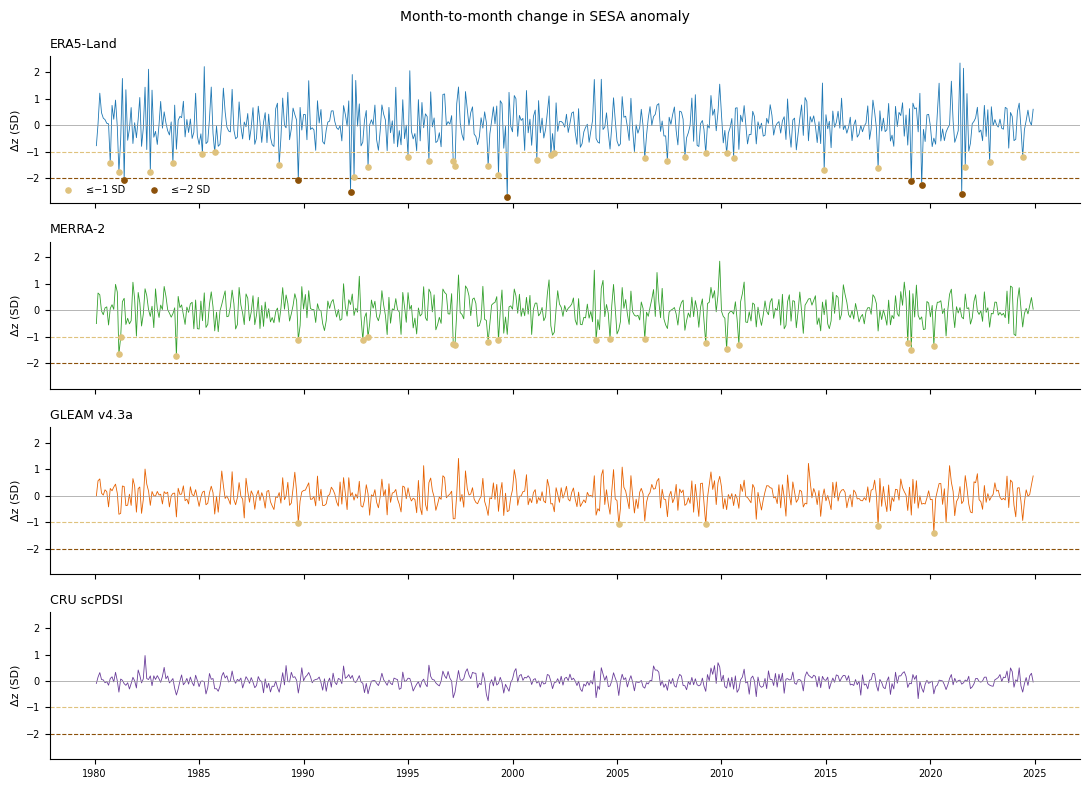

In [53]:
# ========================= 2) month to month ======================
zm = mon.copy()
if RESTANDARDIZE:                                   # per calendar month
    zm = zm.groupby(zm.index.month).transform(lambda x: (x - x.mean()) / x.std(ddof=0))
mi = zm.index.year * 12 + zm.index.month
consecutive = np.r_[False, np.diff(mi) == 1]
dz_mon = zm[names].diff()
dz_mon[~consecutive] = np.nan
month_step = pd.Series([f"{MONTHS[(m - 2) % 12]}→{MONTHS[m - 1]}" for m in zm.index.month], index=zm.index)
MONTH_STEPS = [f"{MONTHS[(m - 2) % 12]}→{MONTHS[m - 1]}" for m in range(1, 13)]

mon_events = find_drops(dz_mon, zm[names], month_step)
mon_counts = count_table(mon_events, MONTH_STEPS, "month step")
mon_events.to_csv(os.path.join(OUT_DIR, "sesa_abrupt_drops_monthly_events.csv"), index=False)
mon_counts.to_csv(os.path.join(OUT_DIR, "sesa_abrupt_drops_monthly_counts.csv"))
print("Month-to-month drops (counts per month step)")
display(mon_counts)
for th in THRESHOLDS:
    print(f"\nShared monthly drops ≤−{th} SD (≥{MIN_AGREE} datasets)")
    display(shared_events(mon_events, th).round(2))

# figure (a): monthly change series, one row per dataset
fig, axes = plt.subplots(len(names), 1, figsize=(11, 2.0 * len(names)), sharex=True, sharey=True)
for ax, n in zip(np.atleast_1d(axes), names):
    ax.plot(dz_mon.index, dz_mon[n], color=COLORS.get(n), lw=0.6)
    for th, col in zip(THRESHOLDS, ["#dfc27d", "#8c510a"]):
        big = dz_mon[n] <= -th
        ax.scatter(dz_mon.index[big], dz_mon[n][big], color=col, s=14, zorder=3, label=f"≤−{th} SD")
        ax.axhline(-th, color=col, lw=0.8, ls="--")
    ax.axhline(0, color="#999999", lw=0.5)
    ax.set_title(n, fontsize=9, loc="left")
    ax.set_ylabel("Δz (SD)", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)
np.atleast_1d(axes)[0].legend(fontsize=7, frameon=False, ncol=2, loc="lower left")
fig.suptitle("Month-to-month change in SESA anomaly", fontsize=10)
fig.tight_layout()
#fig.savefig(os.path.join(FIG_DIR, "sesa_abrupt_drops_monthly_series.png"), dpi=200, bbox_inches="tight")
plt.show()